# Лабораторная работа №2. Классификация

Цель: предсказать, выжил ли пассажир Titanic, сравнить пять моделей с baseline и разобрать ошибки. В столбце Survived 1 означает выживание, 0 — гибель.

Данные: [Titanic Dataset, Kaggle](https://www.kaggle.com/datasets/yasserh/titanic-dataset).

## 1. Импорт библиотек

In [1]:
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

SEED = 42
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110

## 2. Загрузка данных

Проверю размер таблицы, типы, пропуски и повторы. Ноутбук скачивает данные с Kaggle. Для запуска без интернета можно положить Titanic-Dataset.csv рядом с ноутбуком.

In [2]:
filename = 'Titanic-Dataset.csv'
local_csv = next((p for p in (Path(filename), Path('classification') / filename) if p.is_file()), None)
if local_csv is None:
    url = 'https://www.kaggle.com/api/v1/datasets/download/yasserh/titanic-dataset'
    with urlopen(url, timeout=45) as response:
        archive_bytes = response.read()
    with ZipFile(BytesIO(archive_bytes)) as archive:
        data = pd.read_csv(archive.open(filename))
    print('Данные загружены с Kaggle')
else:
    data = pd.read_csv(local_csv)
    print(f'Данные прочитаны из {local_csv}')

print(f'Размер: {data.shape[0]} строк, {data.shape[1]} столбцов')
print(f'Полных повторов: {data.duplicated().sum()}; без PassengerId: '
      f'{data.drop(columns="PassengerId").duplicated().sum()}')
display(pd.DataFrame({'Тип': data.dtypes.astype(str), 'Пропуски': data.isna().sum()}))

Данные прочитаны из Titanic-Dataset.csv
Размер: 891 строк, 12 столбцов
Полных повторов: 0; без PassengerId: 0


,Тип,Пропуски
PassengerId,int64,0
Survived,int64,0
Pclass,int64,0
Name,object,0
Sex,object,0
Age,float64,177
SibSp,int64,0
Parch,int64,0
Ticket,object,0
Fare,float64,0


Пропуски есть в Age (177), Cabin (687) и Embarked (2). Повторов нет. Убираю PassengerId, Name, Ticket и Cabin: по ним можно запоминать отдельных пассажиров и группы, а номер каюты часто неизвестен.

## 3. Разбиение и анализ данных

Для теста оставлю 20% строк. Стратификация сохраняет долю выживших, random_state=42 позволяет повторить разбиение. Оно одинаковое для всех моделей. Связь признаков с исходом смотрю на train.

Train: 712; test: 179
Доля выживших: train 38.3%; test 38.5%


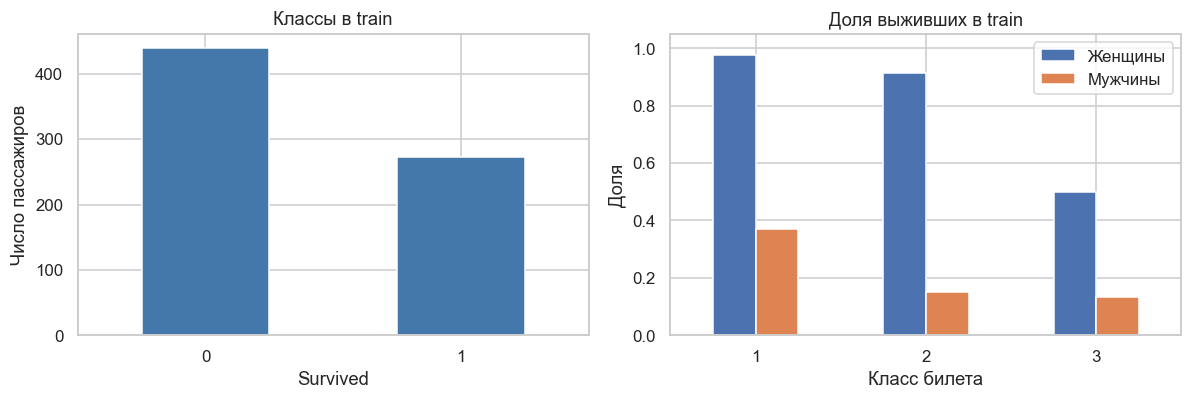

In [3]:
numeric = ['Age', 'SibSp', 'Parch', 'Fare']
categorical = ['Pclass', 'Sex', 'Embarked']
X = data[numeric + categorical].copy()
y = data['Survived']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y,
)
print(f'Train: {len(X_train)}; test: {len(X_test)}')
print(f'Доля выживших: train {y_train.mean():.1%}; test {y_test.mean():.1%}')

train = X_train.assign(Survived=y_train)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
y_train.value_counts().sort_index().plot.bar(ax=axes[0], rot=0, color='#4477AA')
axes[0].set(title='Классы в train', xlabel='Survived', ylabel='Число пассажиров')
rates = train.pivot_table(index='Pclass', columns='Sex', values='Survived', aggfunc='mean')
rates.rename(columns={'female': 'Женщины', 'male': 'Мужчины'}).plot.bar(ax=axes[1], rot=0)
axes[1].set(title='Доля выживших в train', xlabel='Класс билета', ylabel='Доля', ylim=(0, 1.05))
axes[1].legend(title='')
plt.tight_layout()
plt.show()

В train 439 погибших и 273 выживших. Поэтому даже постоянный прогноз 0 даст больше 60% правильных ответов. Выживание связано с полом и классом билета: в первом классе выжили 97% женщин и 37% мужчин, в третьем — 50% и 13%.

## 4. Подготовка данных и метрики

Числовые пропуски заполняю медианой, которая меньше зависит от выбросов. В категориях использую самое частое значение. Пол, порт посадки и класс билета кодирую отдельными one-hot столбцами.

Для KNN и SVM масштабирую числовые признаки: иначе возраст и цена будут по-разному влиять на расстояния. Деревьям это не нужно. Обработка находится внутри Pipeline и обучается только на обучающей части каждого фолда.

Baseline всегда предсказывает самый частый класс. Accuracy — доля правильных ответов. Precision показывает, сколько из предсказанных выживших действительно выжили, Recall — какую долю всех выживших нашла модель. F1 — гармоническое среднее Precision и Recall. Для класса 1 требуется F1 > 0,70; больше — лучше.

In [4]:
def make_model(estimator, scale=False):
    number_steps = [('fill', SimpleImputer(strategy='median'))]
    if scale:
        number_steps.append(('scale', StandardScaler()))
    categories = Pipeline([
        ('fill', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    prep = ColumnTransformer([
        ('num', Pipeline(number_steps), numeric),
        ('cat', categories, categorical),
    ])
    return Pipeline([('prep', prep), ('model', estimator)])

baseline = make_model(DummyClassifier(strategy='most_frequent')).fit(X_train, y_train)
print('Dummy всегда предсказывает класс:', baseline.predict(X_train.iloc[:1])[0])


def metrics(actual, prediction):
    return {
        'Accuracy': accuracy_score(actual, prediction),
        'Precision': precision_score(actual, prediction, zero_division=0),
        'Recall': recall_score(actual, prediction, zero_division=0),
        'F1': f1_score(actual, prediction, zero_division=0),
    }

Dummy всегда предсказывает класс: 0


## 5. Модели и кросс-валидация

Дерево делит пассажиров по признакам. Ограничение глубины и размера листа уменьшает запоминание отдельных примеров. Лес усредняет деревья, бустинг строит их последовательно и исправляет ошибки. SVM ищет разделяющую границу, KNN голосует по ближайшим соседям.

Параметры перебираю на пяти одинаковых стратифицированных фолдах внутри train. Выбираю модель с наибольшим средним F1. Тест в подборе не участвует.

In [5]:
experiments = {
    'Decision Tree': (
        make_model(DecisionTreeClassifier(random_state=SEED)),
        {'max_depth': [3, 5, 8, None], 'min_samples_leaf': [2, 5, 10]},
    ),
    'Random Forest': (
        make_model(RandomForestClassifier(n_estimators=240, random_state=SEED, n_jobs=1)),
        {'max_depth': [4, 7, None], 'min_samples_leaf': [2, 5]},
    ),
    'Gradient Boosting': (
        make_model(GradientBoostingClassifier(random_state=SEED)),
        {'n_estimators': [80, 160], 'max_depth': [2, 3], 'learning_rate': [0.05, 0.10]},
    ),
    'SVM': (
        make_model(SVC(kernel='rbf'), scale=True),
        {'C': [0.5, 1, 3, 10], 'gamma': ['scale', 0.08]},
    ),
    'KNN': (
        make_model(KNeighborsClassifier(), scale=True),
        {'n_neighbors': [5, 9, 15, 21], 'weights': ['uniform', 'distance']},
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fitted = {'Dummy': baseline}
cv_f1 = {'Dummy': cross_val_score(baseline, X_train, y_train, cv=cv, scoring='f1').mean()}
for name, (model, grid) in experiments.items():
    search = GridSearchCV(
        model, {f'model__{key}': values for key, values in grid.items()},
        scoring='f1', cv=cv, n_jobs=1, refit=True, error_score='raise',
    )
    search.fit(X_train, y_train)
    fitted[name] = search.best_estimator_
    cv_f1[name] = search.best_score_
    params = {key.removeprefix('model__'): value for key, value in search.best_params_.items()}
    print(f'{name}: {params}')

cv_f1 = pd.Series(cv_f1, name='Средний CV F1')
selected = cv_f1.loc[list(experiments)].idxmax()
display(cv_f1.to_frame().round(4))
print('Модель, выбранная по CV:', selected)

Decision Tree: {'max_depth': 5, 'min_samples_leaf': 5}


Random Forest: {'max_depth': None, 'min_samples_leaf': 2}


Gradient Boosting: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 160}


SVM: {'C': 1, 'gamma': 0.08}


KNN: {'n_neighbors': 21, 'weights': 'uniform'}


,Средний CV F1
Dummy,0.0000
Decision Tree,0.7214
Random Forest,0.7471
Gradient Boosting,0.7626
SVM,0.7567
KNN,0.7501


Модель, выбранная по CV: Gradient Boosting


По CV выбрал Gradient Boosting: F1 = 0,7626. SVM близко — 0,7567, поэтому на других данных порядок может поменяться.

Дополнительно проверю бустинг с теми же параметрами, удерживая пассажиров с одним билетом в одном фолде. Ticket нужен только для группировки train, в признаки он не входит. Эта проверка не меняет выбор модели и не учитывает родственников с разными билетами.

In [6]:
excluded = {'Survived', 'PassengerId', 'Name', 'Ticket', 'Cabin'}
assert excluded.isdisjoint(X.columns)
ticket_groups = data.loc[X_train.index, 'Ticket']
grouped_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
grouped_f1 = cross_val_score(
    fitted[selected], X_train, y_train, groups=ticket_groups,
    cv=grouped_cv, scoring='f1', error_score='raise',
)
print(f'Обычный CV F1: {cv_f1[selected]:.4f}')
print(f'CV F1 по группам билетов: {grouped_f1.mean():.4f} ± {grouped_f1.std():.4f}')

Обычный CV F1: 0.7626
CV F1 по группам билетов: 0.7448 ± 0.0656


При группировке по билетам средний F1 = 0,7448, стандартное отклонение по фолдам — 0,0656. Качество немного снизилось, но модель справляется и с билетами, которых не было в обучении.

## 6. Сравнение на тесте

Проверю все модели на одних и тех же 179 пассажирах с обычным predict. В матрицах строки — настоящие классы, столбцы — прогнозы. FP: предсказал выживание, пассажир погиб. FN: предсказал гибель, пассажир выжил.

,Accuracy,Precision,Recall,F1,F1 > 0.70
Dummy,0.6145,0.0000,0.0000,0.0000,False
Decision Tree,0.7709,0.7333,0.6377,0.6822,False
Random Forest,0.8045,0.8148,0.6377,0.7154,True
Gradient Boosting,0.8045,0.8036,0.6522,0.7200,True
SVM,0.8268,0.8167,0.7101,0.7597,True
KNN,0.7821,0.7679,0.6232,0.6880,False


Порог прошли: Random Forest, Gradient Boosting, SVM
Модель, выбранная по CV: Gradient Boosting; локальный F1: 0.7200


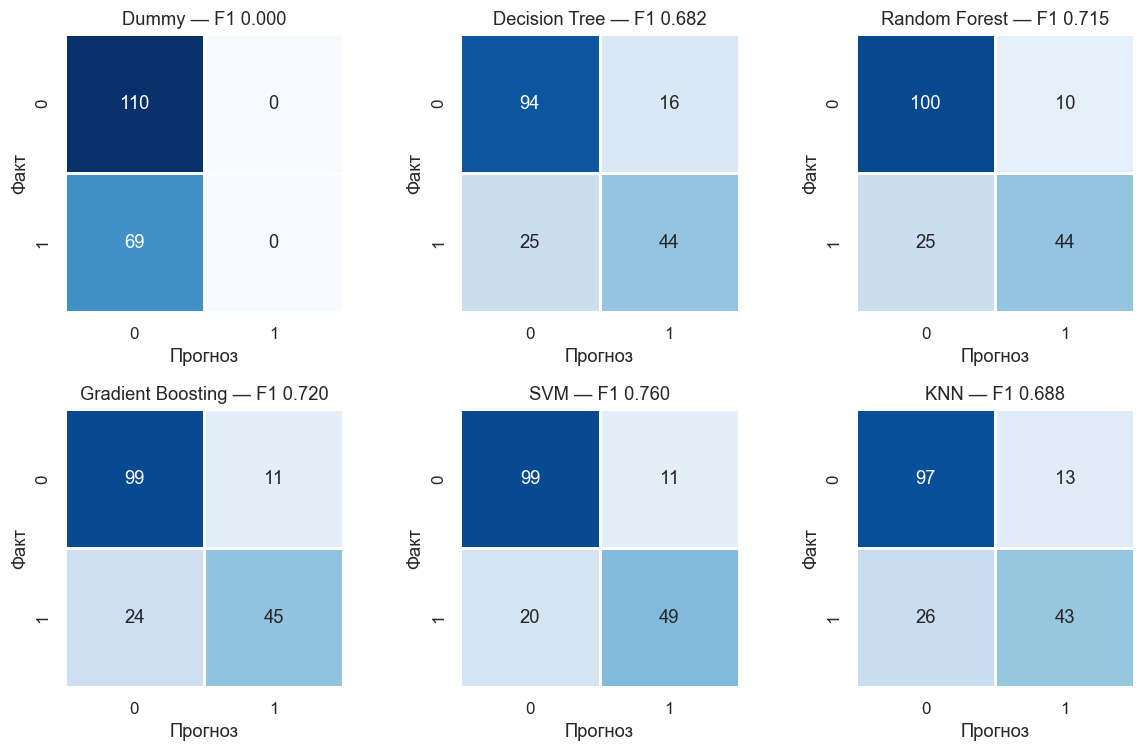

Дерево решений: F1 train = 0.8016, test = 0.6822


In [7]:
predictions = {name: model.predict(X_test) for name, model in fitted.items()}
results = pd.DataFrame.from_dict(
    {name: metrics(y_test, pred) for name, pred in predictions.items()}, orient='index',
)
results['F1 > 0.70'] = results['F1'] > 0.70
display(results.round(4))
print('Порог прошли:', ', '.join(results.index[results['F1 > 0.70']]))
print(f'Модель, выбранная по CV: {selected}; локальный F1: {results.loc[selected, "F1"]:.4f}')

matrices = {name: confusion_matrix(y_test, pred, labels=[0, 1]) for name, pred in predictions.items()}
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
color_max = max(matrix.max() for matrix in matrices.values())
for ax, (name, matrix) in zip(axes.flat, matrices.items()):
    sns.heatmap(matrix, ax=ax, annot=True, fmt='d', cmap='Blues', cbar=False,
                vmin=0, vmax=color_max, square=True, linewidths=0.7)
    ax.set(title=f'{name} — F1 {results.loc[name, "F1"]:.3f}', xlabel='Прогноз', ylabel='Факт')
plt.tight_layout()
plt.show()

tree_train_f1 = f1_score(y_train, fitted['Decision Tree'].predict(X_train))
print(f'Дерево решений: F1 train = {tree_train_f1:.4f}, test = {results.loc["Decision Tree", "F1"]:.4f}')

У baseline Accuracy = 0,6145, но F1 = 0: он не находит выживших. Порог F1 > 0,70 прошли лес, бустинг и SVM. У бустинга F1 = 0,7200, у леса — 0,7154. SVM на этом тесте лучше (0,7597): он пропустил 20 выживших вместо 24 у бустинга. Итоговой моделью остаётся бустинг, выбранный по CV.

У дерева F1 на train = 0,802, на test = 0,682 — есть признаки переобучения. Лес дал меньше FP, чем дерево (10 против 16). KNN пропустил 26 выживших: похожие признаки не всегда означают одинаковый исход.

## 7. Важность признаков

Сравню feature_importances_ у дерева, леса и бустинга. Важности one-hot столбцов складываю для каждого исходного признака.

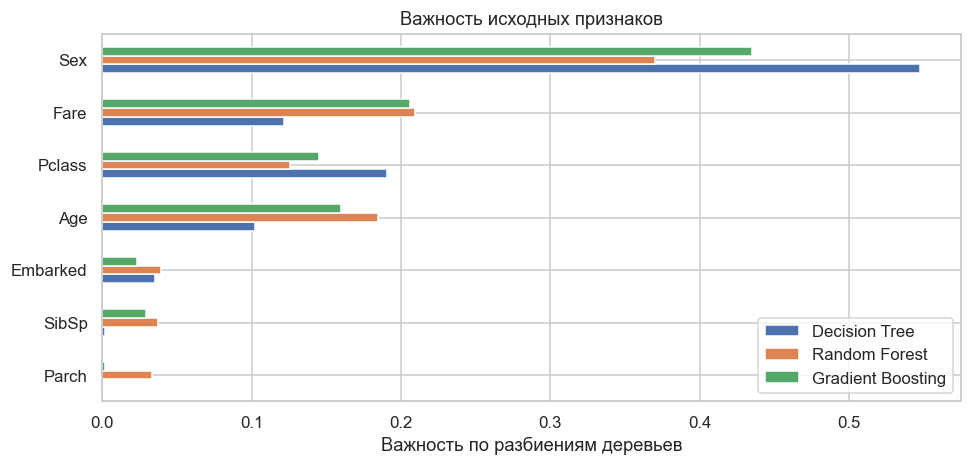

Decision Tree: Sex, Pclass, Fare
Random Forest: Sex, Fare, Age
Gradient Boosting: Sex, Fare, Age


In [8]:
importance = {}
for name in ['Decision Tree', 'Random Forest', 'Gradient Boosting']:
    pipeline = fitted[name]
    encoder = pipeline['prep'].named_transformers_['cat']['encode']
    original_columns = numeric + [
        feature for feature, values in zip(categorical, encoder.categories_) for _ in values
    ]
    weights = pipeline['model'].feature_importances_
    importance[name] = pd.Series(weights, index=original_columns).groupby(level=0).sum()

importance = pd.DataFrame(importance)
order = importance.mean(axis=1).sort_values().index
ax = importance.loc[order].plot.barh(figsize=(9, 4.4))
ax.set(title='Важность исходных признаков', xlabel='Важность по разбиениям деревьев', ylabel='')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()
for name in importance:
    print(f'{name}:', ', '.join(importance[name].nlargest(3).index))

У всех трёх моделей на первом месте Sex. У дерева дальше идут Pclass и Fare, у леса и бустинга — Fare и Age. Это согласуется с различиями по полу и классу билета в первичном анализе.

Важность не доказывает причину выживания: например, цена билета связана с классом. Также деревья могут завышать важность числовых признаков, у которых больше вариантов разбиения.

## 8. Анализ ошибок

Посмотрю ошибки бустинга по полу, классу и возрасту. Рядом с долями показываю размер группы: для маленьких групп проценты менее надёжны.

In [9]:
diagnostics = X_test.assign(actual=y_test, prediction=predictions[selected])
diagnostics['FP'] = diagnostics['actual'].eq(0) & diagnostics['prediction'].eq(1)
diagnostics['FN'] = diagnostics['actual'].eq(1) & diagnostics['prediction'].eq(0)
diagnostics['error'] = diagnostics['FP'] | diagnostics['FN']
diagnostics['Age group'] = pd.cut(
    diagnostics['Age'], [-np.inf, 16, 35, 60, np.inf],
    labels=['до 16', '16–34', '35–59', '60+'], right=False,
).cat.add_categories('Не указан').fillna('Не указан')

group_errors = {}
for column in ['Sex', 'Pclass', 'Age group']:
    group_errors[column] = diagnostics.groupby(column, observed=True).agg(
        Count=('error', 'size'), FP=('FP', 'sum'), FN=('FN', 'sum'),
        Error_rate=('error', 'mean'),
    )
    display(group_errors[column].round(3))

cases = pd.concat([diagnostics[diagnostics['FP']].head(2), diagnostics[diagnostics['FN']].head(2)])
columns = ['Sex', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'actual', 'prediction']
print('Примеры FP и FN; индекс — номер строки CSV с нуля:')
display(cases[columns])

,Count,FP,FN,Error_rate
Sex,,,,
female,61,6,7,0.213
male,118,5,17,0.186


,Count,FP,FN,Error_rate
Pclass,,,,
1,45,5,5,0.222
2,34,1,3,0.118
3,100,5,16,0.210


,Count,FP,FN,Error_rate
Age group,,,,
до 16,17,1,4,0.294
16–34,83,2,10,0.145
35–59,31,4,3,0.226
60+,8,0,2,0.250
Не указан,40,4,5,0.225


Примеры FP и FN; индекс — номер строки CSV с нуля:


,Sex,Pclass,Age,SibSp,Parch,Fare,Embarked,actual,prediction
536,male,1,45.0,0,0,26.5500,S,0,1
698,male,1,49.0,1,1,110.8833,C,0,1
553,male,3,22.0,0,0,7.2250,C,1,0
559,female,3,36.0,1,0,17.4000,S,1,0


У бустинга 99 TN, 11 FP, 24 FN и 45 TP. Чаще он пропускает выживших, причём 17 из 24 FN приходятся на мужчин. Доля ошибок в первом классе — 22,2%, в третьем — 21,0%, во втором — 11,8%. Среди детей до 16 лет ошибок 5 из 17 (29,4%), но группа маленькая.

В строке 698 мужчина 49 лет из первого класса погиб, а модель предсказала выживание. На прогноз могли повлиять первый класс и дорогой билет.

В строке 553 мужчина 22 лет из третьего класса выжил, но прогноз равен 0. В train среди мужчин этого класса выживших мало. В строке 559 женщина из третьего класса тоже выжила, а модель ошиблась: пол и класс дают разные сигналы. Это возможные объяснения, а не доказанные причины ошибок.

## 9. Вывод

По кросс-валидации выбрал бустинг. На локальном тесте F1 = 0,7200 > 0,70. Во всех моделях на деревьях самым важным признаком оказался пол. Бустинг чаще пропускает выживших, чем ошибочно предсказывает выживание. Результат на тесте преподавателя пока неизвестен.

Версии для запуска: Python 3.9, NumPy 1.26.4, pandas 2.3.3, Matplotlib 3.9.4, seaborn 0.13.2, scikit-learn 1.6.1. Ячейки запускать сверху вниз.